In [1]:
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)

df["Month"] = pd.to_datetime(df["Month"])
df.set_index("Month", inplace=True)

series = df["Passengers"].astype(float)

# Train-test split
train_size = int(len(series) * 0.80)
train = series.iloc[:train_size]
test = series.iloc[train_size:]

# Models to compare
orders = [(1,1,1), (2,1,1), (1,1,2), (2,1,2)]

results = []

for order in orders:
    model = ARIMA(train, order=order)
    fitted = model.fit()

    forecast = fitted.forecast(steps=len(test))

    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))

    results.append({
        "ARIMA Order": order,
        "AIC": fitted.aic,
        "MAE": mae,
        "RMSE": rmse
    })

result_df = pd.DataFrame(results)
print(result_df.sort_values("AIC"))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_date

  ARIMA Order          AIC        MAE       RMSE
2   (1, 1, 2)  1057.327535  62.063473  82.635764
3   (2, 1, 2)  1057.516178  63.545311  82.513011
0   (1, 1, 1)  1058.245574  85.254156  97.499620
1   (2, 1, 1)  1058.647616  60.528996  82.621097


In [2]:
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)

df["Month"] = pd.to_datetime(df["Month"])
df.set_index("Month", inplace=True)

series = df["Passengers"].astype(float)

# Train-test split
train_size = int(len(series) * 0.80)
train = series.iloc[:train_size]
test = series.iloc[train_size:]

results = []

for d in [0, 1]:
    model = ARIMA(train, order=(2, d, 2))
    fitted = model.fit()

    forecast = fitted.forecast(steps=len(test))

    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))

    results.append({
        "Differencing (d)": d,
        "AIC": fitted.aic,
        "MAE": mae,
        "RMSE": rmse
    })

print(pd.DataFrame(results))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros 

   Differencing (d)          AIC        MAE        RMSE
0                 0  1074.541309  92.240658  114.886774
1                 1  1057.516178  63.545311   82.513011


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(



Forecast for 6 months:
1961-01-01    439.854863
1961-02-01    465.296545
1961-03-01    500.666051
1961-04-01    535.971401
1961-05-01    561.689094
1961-06-01    571.312667
Freq: MS, Name: predicted_mean, dtype: float64


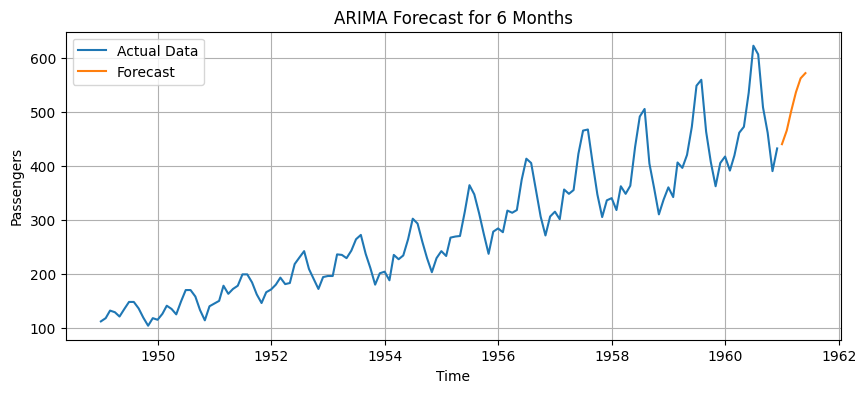


Forecast for 12 months:
1961-01-01    439.854863
1961-02-01    465.296545
1961-03-01    500.666051
1961-04-01    535.971401
1961-05-01    561.689094
1961-06-01    571.312667
1961-07-01    562.972100
1961-08-01    539.729052
1961-09-01    508.528057
1961-10-01    478.147364
1961-11-01    456.747520
1961-12-01    449.697306
Freq: MS, Name: predicted_mean, dtype: float64


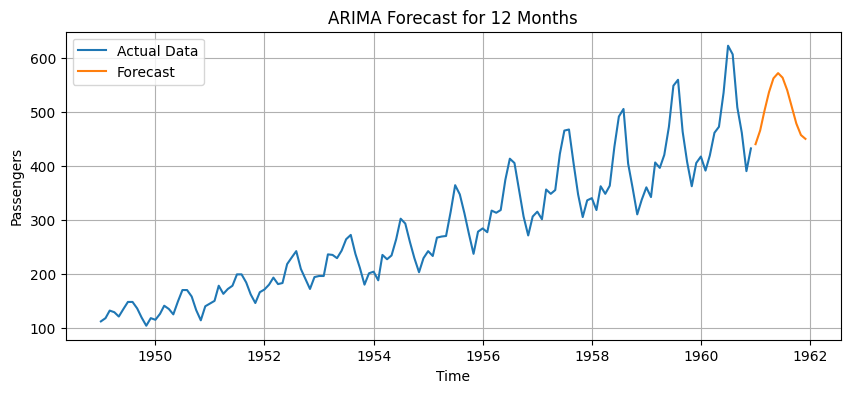


Forecast for 24 months:
1961-01-01    439.854863
1961-02-01    465.296545
1961-03-01    500.666051
1961-04-01    535.971401
1961-05-01    561.689094
1961-06-01    571.312667
1961-07-01    562.972100
1961-08-01    539.729052
1961-09-01    508.528057
1961-10-01    478.147364
1961-11-01    456.747520
1961-12-01    449.697306
1962-01-01    458.251144
1962-02-01    479.396394
1962-03-01    506.858920
1962-04-01    532.943300
1962-05-01    550.673445
1962-06-01    555.642470
1962-07-01    547.085792
1962-08-01    527.922973
1962-09-01    503.803592
1962-10-01    481.459555
1962-11-01    466.839763
1962-12-01    463.540284
Freq: MS, Name: predicted_mean, dtype: float64


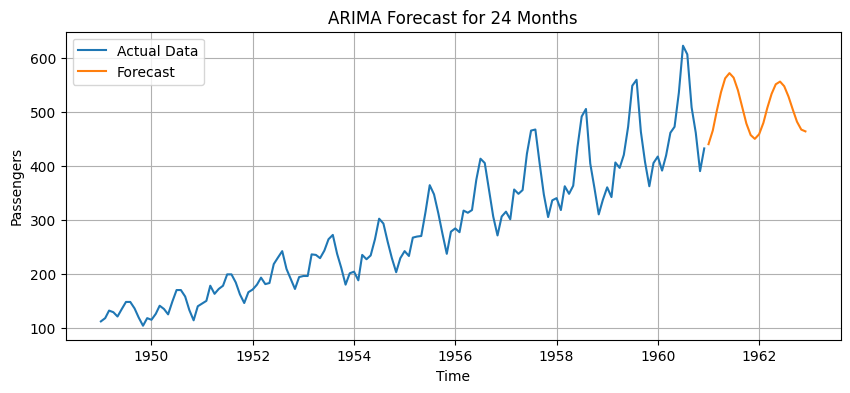

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)

df["Month"] = pd.to_datetime(df["Month"])
df.set_index("Month", inplace=True)

series = df["Passengers"].astype(float)

# Fit ARIMA model on complete dataset
model = ARIMA(series, order=(2, 1, 2))
fitted = model.fit()

# Forecast different horizons
for steps in [6, 12, 24]:

    forecast = fitted.forecast(steps=steps)

    print("\nForecast for", steps, "months:")
    print(forecast)

    plt.figure(figsize=(10, 4))
    plt.plot(series.index, series, label="Actual Data")
    plt.plot(forecast.index, forecast, label="Forecast")

    plt.title(f"ARIMA Forecast for {steps} Months")
    plt.xlabel("Time")
    plt.ylabel("Passengers")
    plt.legend()
    plt.grid()
    plt.show()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


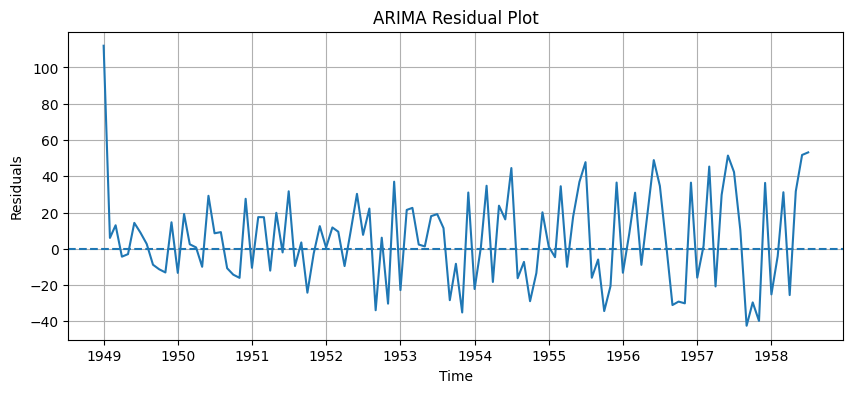

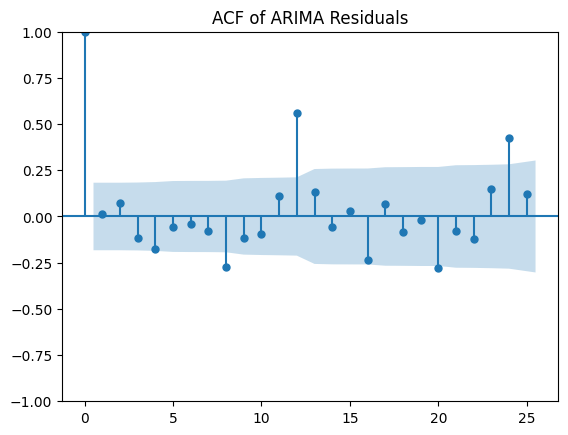

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)

df["Month"] = pd.to_datetime(df["Month"])
df.set_index("Month", inplace=True)

series = df["Passengers"].astype(float)

# Train-test split
train_size = int(len(series) * 0.80)
train = series.iloc[:train_size]

# Fit ARIMA
model = ARIMA(train, order=(2, 1, 2))
fitted = model.fit()

# Extract residuals
residuals = fitted.resid

# Residual plot
plt.figure(figsize=(10, 4))
plt.plot(residuals)
plt.axhline(y=0, linestyle="--")
plt.title("ARIMA Residual Plot")
plt.xlabel("Time")
plt.ylabel("Residuals")
plt.grid()
plt.show()

# Residual ACF
plot_acf(residuals, lags=25)
plt.title("ACF of ARIMA Residuals")
plt.show()